In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from regression.model import LinearRegression, standardize, r2, rmse, mae

# Synthetic data with known coefficients
rng = np.random.default_rng(42)
X = rng.normal(size=(200, 3))
true_beta = np.array([2.0, 1.5, -0.7, 3.0])  # intercept + 3 coefficients
y = true_beta[0] + X @ true_beta[1:] + rng.normal(scale=0.5, size=200)

# 1) Closed-form solution
m1 = LinearRegression().fit(X, y)

# 2) Gradient descent
m2 = LinearRegression().fit_gradient_descent(X, y, lr=0.05, n_iter=2000)

# 3) NumPy reference
X1 = np.column_stack([np.ones(len(X)), X])
ref_beta, *_ = np.linalg.lstsq(X1, y, rcond=None)

print(pd.DataFrame({
    "true": true_beta,
    "closed_form": m1.beta,
    "gradient_descent": m2.beta,
    "lstsq": ref_beta,
}).round(4))

np.testing.assert_allclose(m1.beta, ref_beta, rtol=1e-8)
print("\nClosed-form solution matches lstsq ✓")
y_pred = m1.predict(X)
print(f"R²={r2(y, y_pred):.4f}  RMSE={rmse(y, y_pred):.4f}  MAE={mae(y, y_pred):.4f}")

   true  closed_form  gradient_descent   lstsq
0   2.0       1.9815            1.9815  1.9815
1   1.5       1.5184            1.5184  1.5184
2  -0.7      -0.7038           -0.7038 -0.7038
3   3.0       2.9742            2.9742  2.9742

Closed-form solution matches lstsq ✓
R²=0.9737  RMSE=0.5065  MAE=0.4106


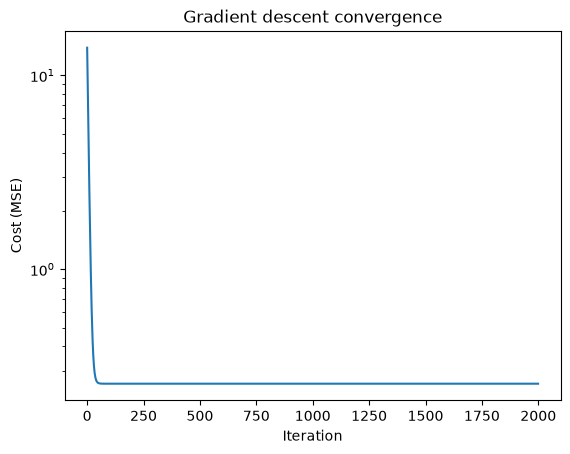

In [3]:
plt.plot(m2.cost_history)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Cost (MSE)")
plt.title("Gradient descent convergence")
plt.show()

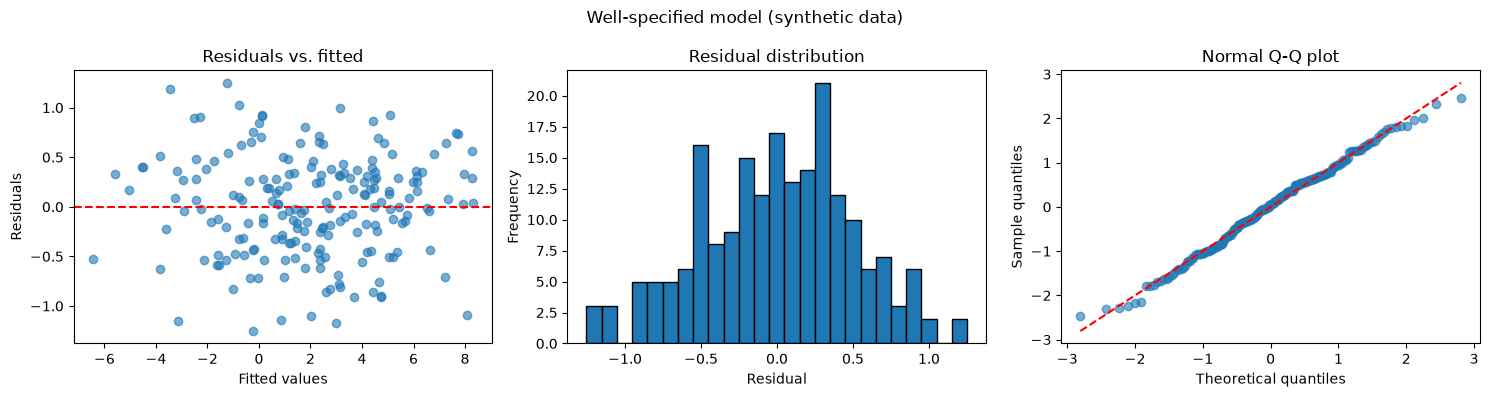

Mean of residuals: 8.00e-16
Correlation with each predictor: [-0.  0. -0.]


In [4]:
from regression.diagnostics import plot_diagnostics, residuals

y_pred = m1.predict(X)
plot_diagnostics(y, y_pred, title="Well-specified model (synthetic data)")

# Sanity checks: with an intercept, OLS residuals have mean ~0
# and are orthogonal to every predictor
res = residuals(y, y_pred)
print(f"Mean of residuals: {res.mean():.2e}")
print("Correlation with each predictor:",
      np.round([np.corrcoef(X[:, j], res)[0, 1] for j in range(X.shape[1])], 10))

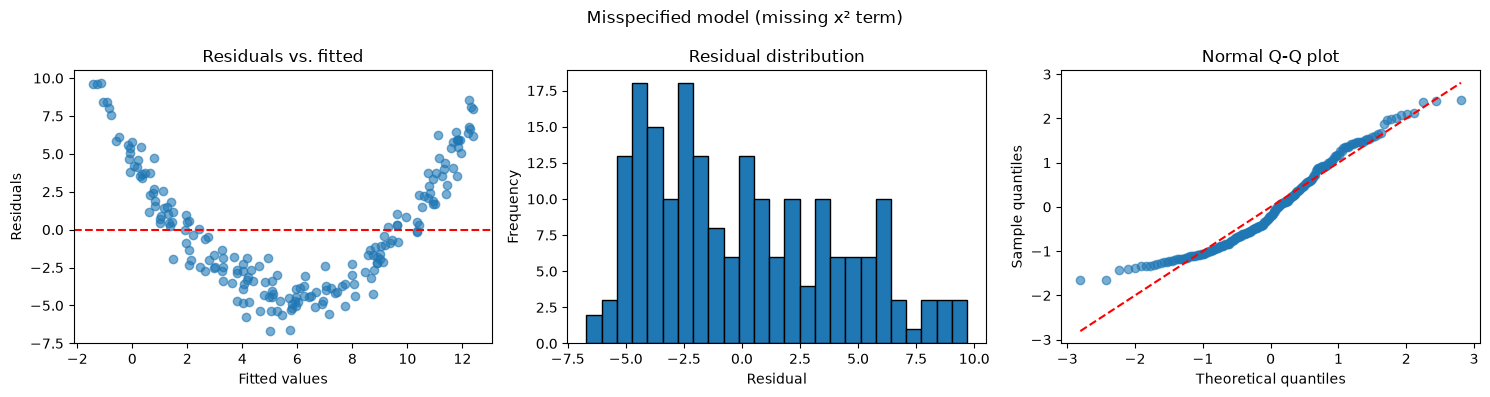

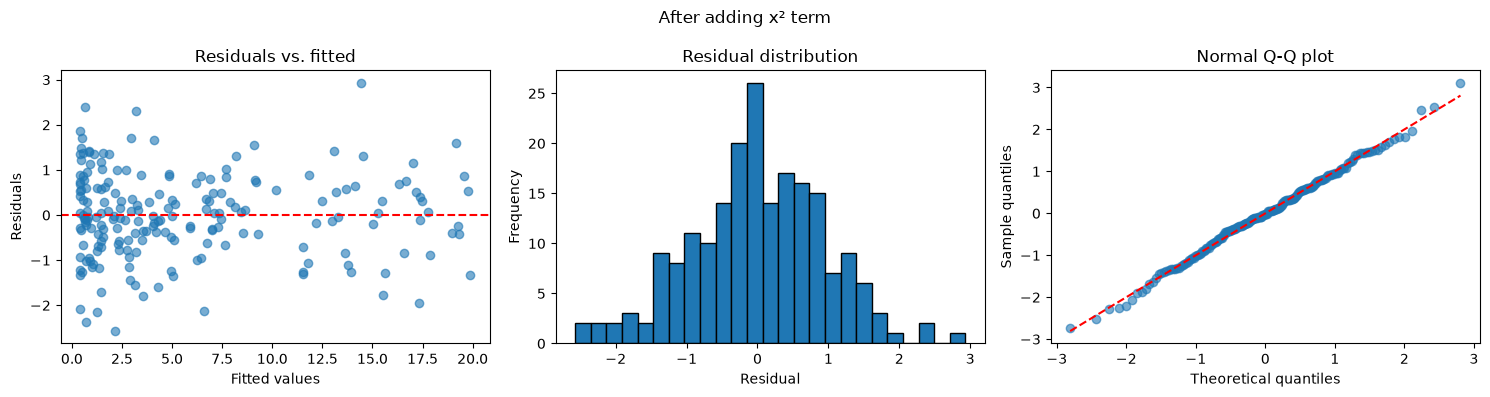

In [5]:
# Misspecified model: the true relationship is quadratic, we fit a line
x = rng.uniform(-3, 3, size=200)
y_quad = 1 + 2 * x + 1.5 * x**2 + rng.normal(scale=1.0, size=200)

m_bad = LinearRegression().fit(x, y_quad)
plot_diagnostics(y_quad, m_bad.predict(x), title="Misspecified model (missing x² term)")

# Fix: add the quadratic term
X_quad = np.column_stack([x, x**2])
m_fix = LinearRegression().fit(X_quad, y_quad)
plot_diagnostics(y_quad, m_fix.predict(X_quad), title="After adding x² term")

## REAL DATA: AUTO MPG

In [6]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]

df = pd.read_csv(url, sep=r"\s+", names=cols, na_values="?")
print(df.shape, df.isna().sum()[df.isna().sum() > 0].to_dict())
df = df.dropna().reset_index(drop=True)
df.describe().round(2)

(398, 9) {'horsepower': 6}


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,392.00,392.00,392.00,392.00,392.00,392.00,392.00,392.00
mean,23.45,5.47,194.41,104.47,2977.58,15.54,75.98,1.58
std,7.81,1.71,104.64,38.49,849.40,2.76,3.68,0.81
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00,1.00
25%,17.00,4.00,105.00,75.00,2225.25,13.78,73.00,1.00
50%,22.75,4.00,151.00,93.50,2803.50,15.50,76.00,1.00
75%,29.00,8.00,275.75,126.00,3614.75,17.02,79.00,2.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00,3.00


In [7]:
features = ["weight", "horsepower", "displacement", "acceleration", "model_year"]
X_auto = df[features].to_numpy()
y_auto = df["mpg"].to_numpy()

# Train/test split (80/20)
rng_auto = np.random.default_rng(42)
idx = rng_auto.permutation(len(df))
n_train = int(0.8 * len(df))
train, test = idx[:n_train], idx[n_train:]

# Standardize using TRAIN statistics only (avoids data leakage)
X_train, mu, sigma = standardize(X_auto[train])
X_test = (X_auto[test] - mu) / sigma

cf = LinearRegression().fit(X_train, y_auto[train])
gd = LinearRegression().fit_gradient_descent(X_train, y_auto[train], lr=0.1, n_iter=3000)

print(pd.DataFrame({"closed_form": cf.beta, "gradient_descent": gd.beta},
                   index=["intercept"] + features).round(3))

for name, m in [("closed_form", cf), ("gradient_descent", gd)]:
    p = m.predict(X_test)
    print(f"{name}: R²={r2(y_auto[test], p):.3f}  RMSE={rmse(y_auto[test], p):.3f}  MAE={mae(y_auto[test], p):.3f}")

              closed_form  gradient_descent
intercept          23.588            23.588
weight             -6.221            -6.221
horsepower          0.363             0.363
displacement        0.351             0.351
acceleration        0.389             0.389
model_year          2.729             2.729
closed_form: R²=0.767  RMSE=3.617  MAE=2.698
gradient_descent: R²=0.767  RMSE=3.617  MAE=2.698


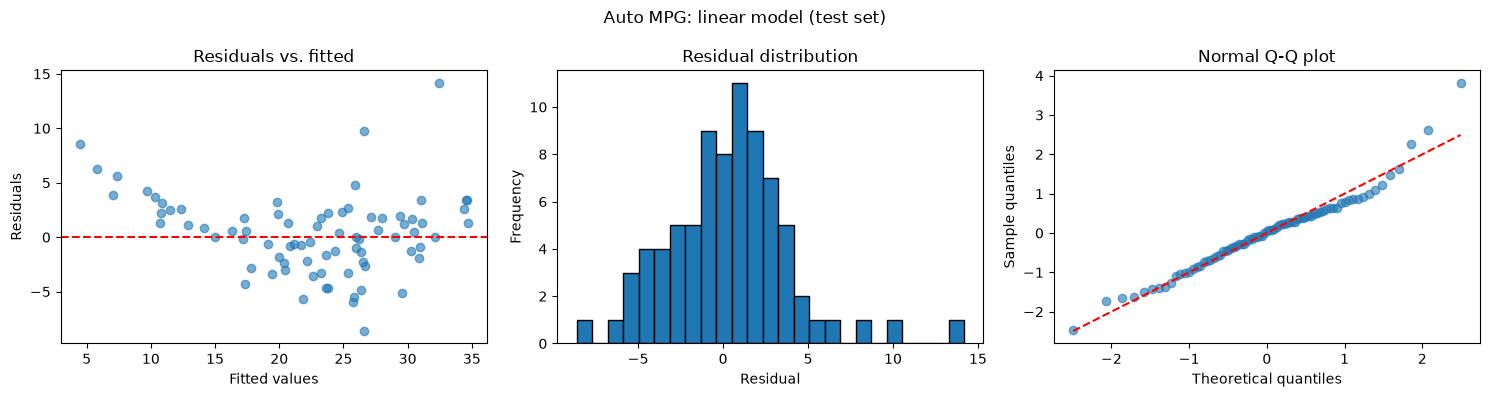

In [9]:
plot_diagnostics(y_auto[test], cf.predict(X_test),
                 title="Auto MPG: linear model (test set)",
                 save_path="../figures/diagnostics_linear.png")



Linear   : R²=0.767 RMSE=3.617
Log(mpg) : R²=0.832 RMSE=3.069


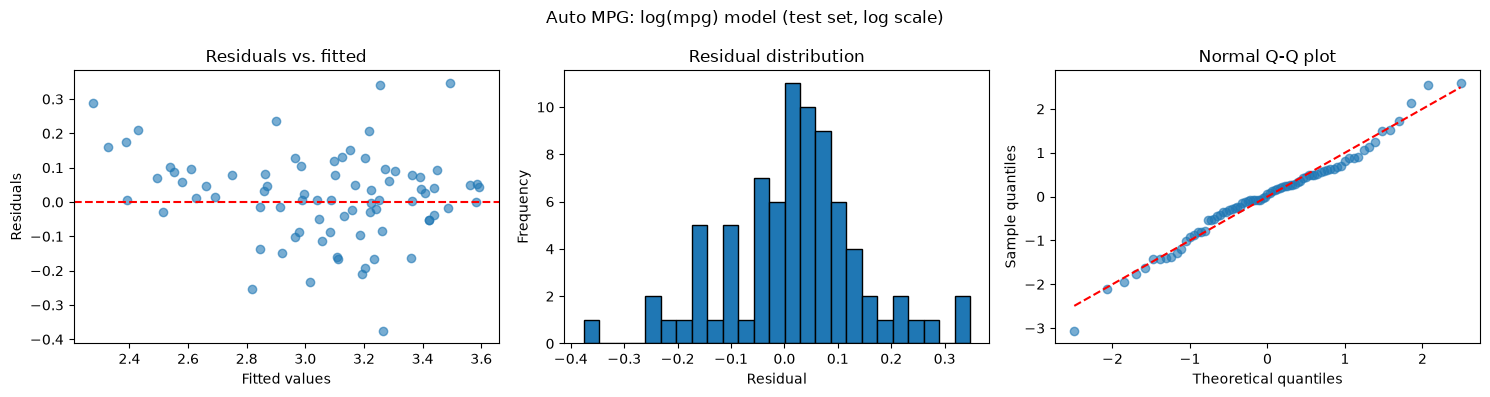

In [10]:
# Fit on log scale, evaluate on the original scale
cf_log = LinearRegression().fit(X_train, np.log(y_auto[train]))
pred_log = np.exp(cf_log.predict(X_test))

print("Linear   :", f"R²={r2(y_auto[test], cf.predict(X_test)):.3f}",
      f"RMSE={rmse(y_auto[test], cf.predict(X_test)):.3f}")
print("Log(mpg) :", f"R²={r2(y_auto[test], pred_log):.3f}",
      f"RMSE={rmse(y_auto[test], pred_log):.3f}")

plot_diagnostics(np.log(y_auto[test]), cf_log.predict(X_test),
                 title="Auto MPG: log(mpg) model (test set, log scale)",
                 save_path="../figures/diagnostics_log.png")

In [11]:
res_log = np.log(y_auto[test]) - cf_log.predict(X_test)
worst = np.argsort(np.abs(res_log))[:0:-1][:3]  # 3 largest |residuals|
print(df.iloc[test[worst]][["car_name", "mpg", "weight", "horsepower", "model_year"]])

                car_name   mpg  weight  horsepower  model_year
110            maxda rx3  18.0  2124.0        90.0          73
320            mazda glc  46.6  2110.0        65.0          80
325  audi 5000s (diesel)  36.4  2950.0        67.0          80


In [12]:
from regression.inference import coef_summary

coef_summary(cf_log, X_train, np.log(y_auto[train]), names=features)

,coef,std_err,t,ci_low,ci_high
intercept,3.1037,0.0068,455.1857,3.0903,3.1170
weight,-0.2348,0.0221,-10.6352,-0.2780,-0.1915
horsepower,-0.0276,0.0205,-1.3448,-0.0679,0.0126
displacement,-0.0090,0.0224,-0.4006,-0.0529,0.0349
acceleration,-0.0009,0.0110,-0.0860,-0.0225,0.0206
model_year,0.1086,0.0076,14.2517,0.0937,0.1235


In [13]:
rng_b = np.random.default_rng(0)
y_log = np.log(y_auto[train])
boots = []
for _ in range(1000):
    i = rng_b.integers(0, len(X_train), len(X_train))
    boots.append(LinearRegression().fit(X_train[i], y_log[i]).beta)

boot_se = np.std(boots, axis=0, ddof=1)
print(pd.DataFrame({
    "analytic_se": coef_summary(cf_log, X_train, y_log, names=features)["std_err"],
    "bootstrap_se": boot_se.round(4),
})) 

              analytic_se  bootstrap_se
intercept          0.0068        0.0067
weight             0.0221        0.0268
horsepower         0.0205        0.0233
displacement       0.0224        0.0304
acceleration       0.0110        0.0129
model_year         0.0076        0.0074


In [14]:
from regression.inference import coef_summary, robust_se

summary = coef_summary(cf_log, X_train, y_log, names=features)
pd.DataFrame({
    "analytic": summary["std_err"],
    "robust_HC3": robust_se(cf_log, X_train, y_log).round(4),
    "bootstrap": boot_se.round(4),
})

,analytic,robust_HC3,bootstrap
intercept,0.0068,0.0069,0.0067
weight,0.0221,0.0284,0.0268
horsepower,0.0205,0.0253,0.0233
displacement,0.0224,0.0312,0.0304
acceleration,0.0110,0.0136,0.0129
model_year,0.0076,0.0078,0.0074


In [15]:
print(pd.DataFrame(np.corrcoef(X_train.T), index=features, columns=features).round(2))

              weight  horsepower  displacement  acceleration  model_year
weight          1.00        0.86          0.93         -0.42       -0.32
horsepower      0.86        1.00          0.90         -0.69       -0.42
displacement    0.93        0.90          1.00         -0.55       -0.38
acceleration   -0.42       -0.69         -0.55          1.00        0.26
model_year     -0.32       -0.42         -0.38          0.26        1.00


In [17]:
cols = [features.index(f) for f in ["weight", "horsepower", "model_year"]]
cf_small = LinearRegression().fit(X_train[:, cols], np.log(y_auto[train]))
pred_small = np.exp(cf_small.predict(X_test[:, cols]))

print("Full  :", f"R²={r2(y_auto[test], pred_log):.3f}  RMSE={rmse(y_auto[test], pred_log):.3f}")
print("Small :", f"R²={r2(y_auto[test], pred_small):.3f}  RMSE={rmse(y_auto[test], pred_small):.3f}")

Full  : R²=0.832  RMSE=3.069
Small : R²=0.833  RMSE=3.068
